<a href="https://colab.research.google.com/github/kafilatmusa1-droid/marketing-regression/blob/main/Pothole_Final_Sprint.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Set up, find (or build) the Nigerian dataset, and check it
!pip install -q ultralytics folium
import os, glob, csv, random, shutil, subprocess, collections, json, hashlib, datetime
from pathlib import Path
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

PP = '/content/drive/MyDrive/PotholeProject'
ND = PP + '/Nigeria_data'

def n_images(ds):
    return sum(len(list((Path(ds) / s / 'images').glob('*.*'))) for s in ('train', 'val', 'test'))

def find_dataset():
    best, best_n = None, 0
    for p in glob.glob('/content/*/') + glob.glob('/content/*/*/'):
        if p.startswith('/content/drive') or p.startswith('/content/sample_data'):
            continue
        if all((Path(p) / s / 'images').is_dir() for s in ('train', 'val', 'test')):
            n = n_images(p)
            if n > best_n:
                best, best_n = p.rstrip('/'), n
    return best if best_n > 100 else None

def build_dataset():
    IMG = '/content/ng_tmp/nigeria_final/images'
    LAB = '/content/ng_labels'
    DSB = '/content/ngds'
    if not os.path.exists(IMG):
        subprocess.run(['unzip', '-q', '-o', ND + '/nigeria_final.zip', '-d', '/content/ng_tmp'], check=True)
    os.makedirs(LAB, exist_ok=True)
    for z in sorted(glob.glob(ND + '/Nigeria_labels/*.zip')):
        subprocess.run(['unzip', '-q', '-o', z, '-d', LAB], check=True)
    lab = {os.path.splitext(os.path.basename(f))[0]: f for f in glob.glob(LAB + '/**/NG_*.txt', recursive=True)}
    flagged = {r['picture'] for r in csv.DictReader(open(ND + '/review_flags.csv', encoding='utf-8-sig'))
               if r['flag'] == 'one_box_may_cover_several_potholes'}
    junk = {'NG_0364', 'NG_0316', 'NG_0682', 'NG_0817', 'NG_0747', 'NG_0808'}
    doubtful = {'NG_0675', 'NG_0359', 'NG_0326', 'NG_0263'}
    last = max(lab)
    all_ids = sorted(os.path.splitext(f)[0] for f in os.listdir(IMG) if f.endswith('.jpg'))
    def parse(k):
        boxes, bad = [], 0
        for line in open(lab[k]).read().strip().splitlines():
            p = line.split()
            try:
                c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:5]]
                ok = len(p) == 5 and c in range(4) and w > 0 and h > 0 and xc - w / 2 > -0.002 and yc - h / 2 > -0.002 and xc + w / 2 < 1.002 and yc + h / 2 < 1.002
            except (ValueError, IndexError):
                ok = False
            if ok:
                boxes.append(line.strip())
            else:
                bad += 1
        return boxes, bad
    pos, neg, excluded = [], [], {}
    for k in all_ids:
        if k in flagged or k in junk or k in doubtful:
            excluded[k] = 'flagged_or_junk_or_doubtful'
        elif k in lab:
            boxes, bad = parse(k)
            if bad or not boxes:
                excluded[k] = 'invalid_label'
            else:
                pos.append(k)
        elif k < last:
            neg.append(k)
        else:
            excluded[k] = 'not_reviewed_yet'
    random.seed(42)
    split_of = {}
    for group in (pos, neg):
        g = group[:]
        random.shuffle(g)
        n = len(g); n_tr, n_va = int(n * 0.70), int(n * 0.15)
        for k in g[:n_tr]: split_of[k] = 'train'
        for k in g[n_tr:n_tr + n_va]: split_of[k] = 'val'
        for k in g[n_tr + n_va:]: split_of[k] = 'test'
    shutil.rmtree(DSB, ignore_errors=True)
    for s in ('train', 'val', 'test'):
        os.makedirs(DSB + '/' + s + '/images'); os.makedirs(DSB + '/' + s + '/labels')
    rows = []
    for k, s in sorted(split_of.items()):
        shutil.copy(IMG + '/' + k + '.jpg', DSB + '/' + s + '/images/' + k + '.jpg')
        out = DSB + '/' + s + '/labels/' + k + '.txt'
        if k in lab:
            boxes, _ = parse(k)
            open(out, 'w').write('\n'.join(boxes))
            rows.append([k, s, 'labelled', len(boxes), ''])
        else:
            open(out, 'w').write('')
            rows.append([k, s, 'background_not_verified_clean', 0, ''])
    for k, why in sorted(excluded.items()):
        rows.append([k, 'excluded', '', '', why])
    with open(ND + '/ngds_manifest.csv', 'w', newline='', encoding='utf-8-sig') as f:
        w = csv.writer(f); w.writerow(['picture', 'split', 'status', 'boxes', 'reason_left_out']); w.writerows(rows)
    print('Built dataset: labelled', len(pos), '| background', len(neg), '| left out', len(excluded))
    return DSB

DS = find_dataset()
if DS is None:
    zips = [z for z in glob.glob(PP + '/**/*.zip', recursive=True) if any(w in os.path.basename(z).lower() for w in ('ngds', 'stratified'))]
    for z in zips:
        subprocess.run(['unzip', '-q', '-o', z, '-d', '/content'])
        DS = find_dataset()
        if DS:
            print('Restored the dataset from', z)
            break
if DS is None:
    print('No ready dataset found, so I am building one from your labelled Nigerian pictures...')
    DS = build_dataset()
print('USING DATASET FOLDER:', DS)

DATA = DS + '/data_final.yaml'
with open(DATA, 'w') as f:
    f.write('path: ' + DS + '\ntrain: train/images\nval: val/images\ntest: test/images\nnames:\n  0: D00\n  1: D10\n  2: D20\n  3: D40\n')
open('/content/DS_PATH.txt', 'w').write(DS)

seen, total_problems = {}, 0
print()
print('%-6s %9s %7s %7s %7s %7s %7s %9s' % ('split', 'pictures', 'D00', 'D10', 'D20', 'D40', 'empty', 'problems'))
for s in ('train', 'val', 'test'):
    imgs = sorted((Path(DS) / s / 'images').glob('*.*'))
    label_files = list((Path(DS) / s / 'labels').glob('*.txt'))
    label_names = {p.stem for p in label_files}
    counts, problems, empty = collections.Counter(), 0, 0
    for p in label_files:
        lines = [ln.split() for ln in p.read_text().split('\n') if ln.strip()]
        if not lines:
            empty += 1
        for parts in lines:
            try:
                ok = len(parts) == 5 and int(float(parts[0])) in range(4) and all(0 <= float(v) <= 1 for v in parts[1:])
            except ValueError:
                ok = False
            if ok:
                counts[int(float(parts[0]))] += 1
            else:
                problems += 1
    problems += len([i for i in imgs if i.stem not in label_names])
    total_problems += problems
    print('%-6s %9d %7d %7d %7d %7d %7d %9d' % (s, len(imgs), counts[0], counts[1], counts[2], counts[3], empty, problems))
    for i in imgs:
        seen.setdefault(i.stem, []).append(s)
overlap = [k for k, v in seen.items() if len(v) > 1]
print('Pictures in more than one split:', len(overlap))
assert len(seen) > 100, 'Dataset looks empty: stop and send me this output'
assert total_problems == 0 and len(overlap) == 0, 'Dataset problem found: stop and send me this output'
print('\nCELL 1 DONE: dataset is ready and checked.')


Mounted at /content/drive
Restored the dataset from /content/drive/MyDrive/PotholeProject/Nigeria_data/ngds_v1.zip
USING DATASET FOLDER: /content/ngds

split   pictures     D00     D10     D20     D40   empty  problems
train        410      70      31      39     299     101         0
val           87      16       7       6      56      21         0
test          90      12       3       9      64      23         0
Pictures in more than one split: 0

CELL 1 DONE: dataset is ready and checked.


In [2]:
# CELL 2: Train M1 and M2 on the GPU, compare M0, M1, M2 (needs the GPU)
import os, csv, json
import torch
from ultralytics import YOLO

PP = '/content/drive/MyDrive/PotholeProject'
BASE = PP + '/runs/baseline_yolo26s/weights/best.pt'
RUNS = PP + '/runs_ng'
DS = open('/content/DS_PATH.txt').read().strip()
DATA = DS + '/data_final.yaml'
assert torch.cuda.is_available(), 'No GPU: click Runtime, then Change runtime type, choose T4 GPU, Save, then run Cell 1 again and this cell'
assert os.path.exists(BASE), 'Baseline model file not found on Drive: stop and tell me'
os.makedirs(RUNS, exist_ok=True)

def evaluate(weights, split, tag):
    m = YOLO(weights).val(data=DATA, split=split, imgsz=640, batch=16, device=0, plots=False, verbose=False,
                          project=RUNS + '/eval', name=tag + '_' + split, exist_ok=True)
    idx = list(m.box.ap_class_index)
    pot = float(m.box.ap50[idx.index(3)]) if 3 in idx else float('nan')
    return dict(pothole_map50=pot, map50=float(m.box.map50), map5095=float(m.box.map), precision=float(m.box.mp), recall=float(m.box.mr))

def train(tag, start, epochs, patience, **extra):
    best = RUNS + '/' + tag + '/weights/best.pt'
    marker = RUNS + '/' + tag + '/DONE.txt'
    if os.path.exists(marker) and os.path.exists(best):
        print('ALREADY TRAINED, skipping (safe after a crash):', tag)
        return best
    model = YOLO(start)
    model.train(data=DATA, epochs=epochs, patience=patience, imgsz=640, batch=16, workers=2, seed=0, cache='ram',
                project=RUNS, name=tag, exist_ok=True, plots=True, **extra)
    del model
    torch.cuda.empty_cache()
    open(marker, 'w').write('finished')
    return best

weights = {'M0 RDD2022 model': BASE}
weights['M1 fine-tuned'] = train('M1_finetune', BASE, 60, 15, optimizer='AdamW', lr0=0.0005, warmup_epochs=1)
weights['M2 Nigerian only'] = train('M2_nigerian_only', 'yolo26s.pt', 100, 30)

val = {k: evaluate(w, 'val', k.split()[0]) for k, w in weights.items()}
print('\nVALIDATION RESULTS (used to choose the winner)')
print('%-20s %16s %12s' % ('model', 'pothole mAP@0.5', 'all mAP@0.5'))
for k, r in val.items():
    print('%-20s %16.3f %12.3f' % (k, r['pothole_map50'], r['map50']))
best_pot = max(r['pothole_map50'] for r in val.values())
close = [k for k, r in val.items() if best_pot - r['pothole_map50'] <= 0.02]
winner = max(close, key=lambda k: val[k]['map50'])
print('\nWINNER BY THE RULE (write this down before reading the test numbers):', winner)

test = {k: evaluate(w, 'test', k.split()[0]) for k, w in weights.items()}
print('\nTEST RESULTS (report these; never use them to choose)')
print('%-20s %16s %12s %14s %10s %8s' % ('model', 'pothole mAP@0.5', 'all mAP@0.5', 'all mAP@0.5:95', 'precision', 'recall'))
for k, r in test.items():
    print('%-20s %16.3f %12.3f %14.3f %10.3f %8.3f' % (k, r['pothole_map50'], r['map50'], r['map5095'], r['precision'], r['recall']))
rows = [[k, 'val'] + list(val[k].values()) for k in val] + [[k, 'test'] + list(test[k].values()) for k in test]
with open(RUNS + '/results_T2.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['model', 'split', 'pothole_map50', 'map50', 'map5095', 'precision', 'recall'])
    w.writerows(rows)
json.dump({'winner_by_validation': winner, 'weights': weights}, open(RUNS + '/winner_T2.json', 'w'), indent=2)
print('\nCELL 2 DONE: results and models saved to Drive (runs_ng).')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ngds/data_final.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

TRAINING CHARTS FROM: /content/drive/MyDrive/PotholeProject/runs_ng/M2_nigerian_only
COPIED: ['results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']


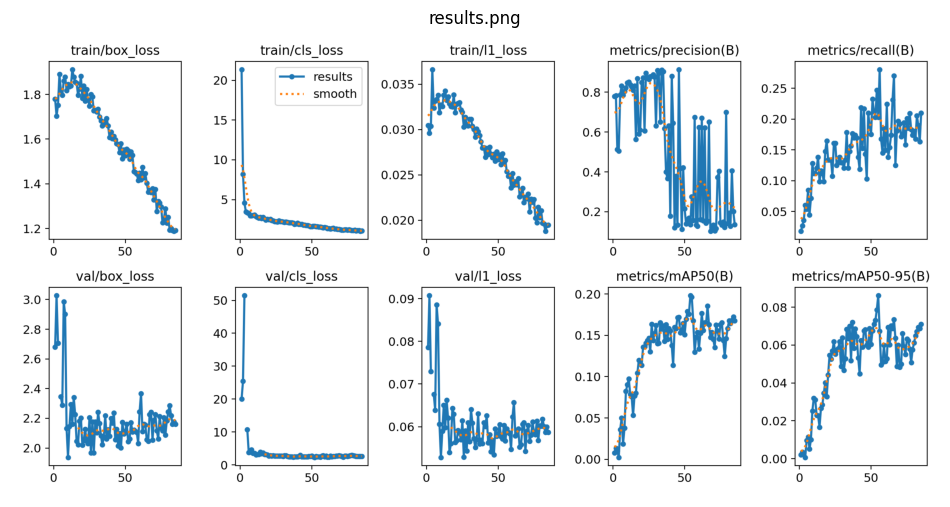

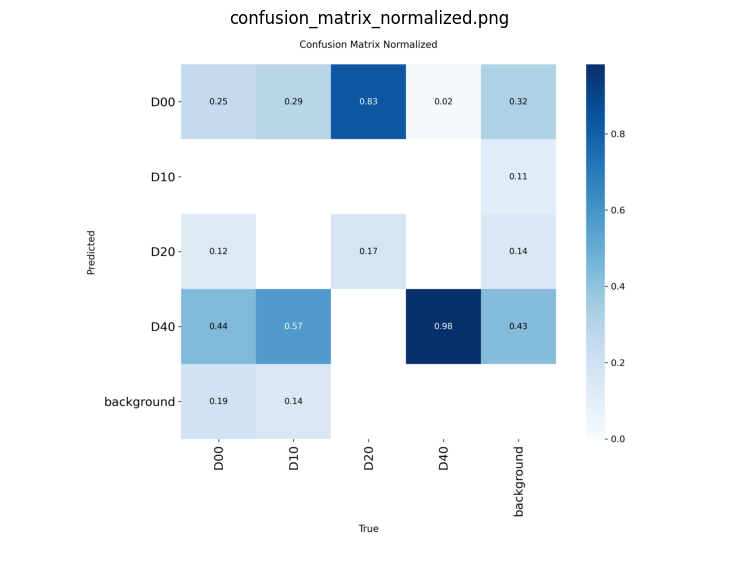


[Warning] exports_T3.json not found. Falling back to uncompressed winning model.


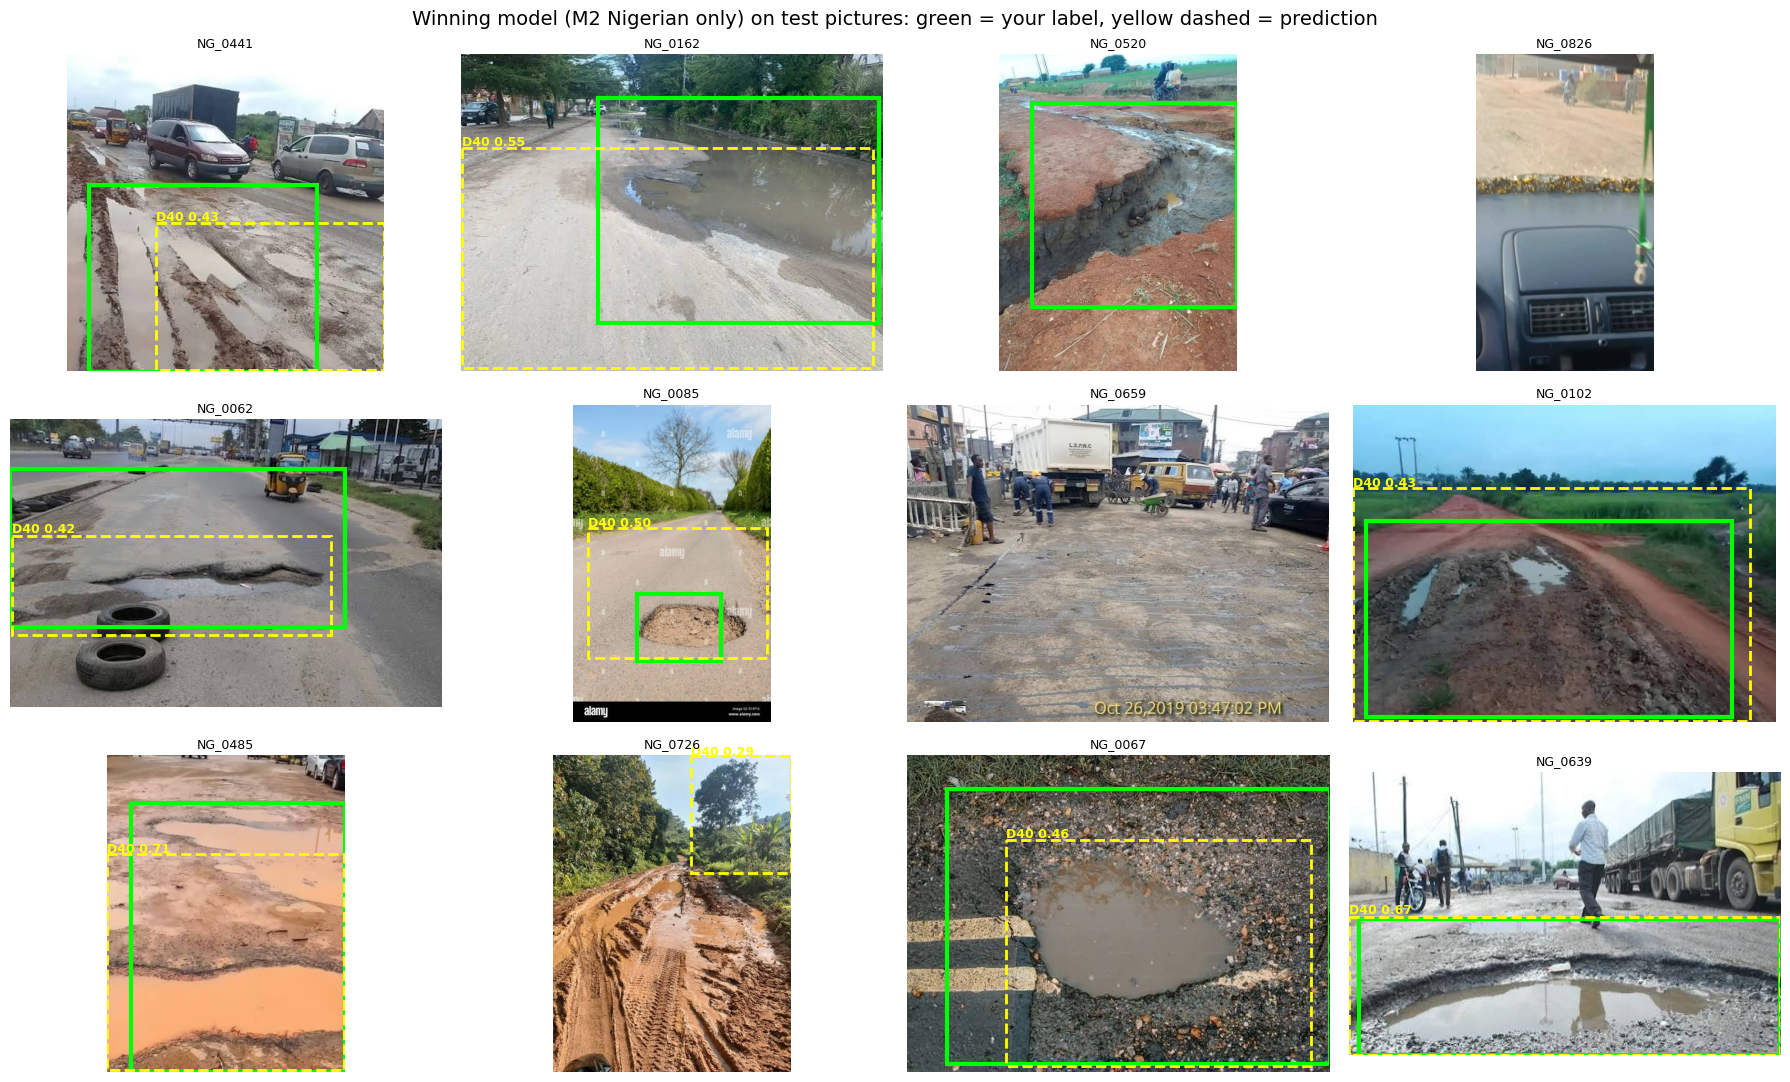


CELL 4 DONE: figures saved to Drive (figures_ng).


In [5]:
# CELL 4: Figures for the report: training charts and example detections from the model
import os, json, glob, shutil, random
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

PP = '/content/drive/MyDrive/PotholeProject'
RUNS = PP + '/runs_ng'
EXP = PP + '/exports_ng'
FIG = PP + '/figures_ng'
os.makedirs(FIG, exist_ok=True)
DS = open('/content/DS_PATH.txt').read().strip()
info = json.load(open(RUNS + '/winner_T2.json'))
name = info['winner_by_validation']
folders = {'M0': PP + '/runs/baseline_yolo26s', 'M1': RUNS + '/M1_finetune', 'M2': RUNS + '/M2_nigerian_only'}
run_dir = folders[name.split()[0]]
print('TRAINING CHARTS FROM:', run_dir)
copied = []
for fn in ['results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'PR_curve.png', 'F1_curve.png']:
    p = run_dir + '/' + fn
    if os.path.exists(p):
        shutil.copy(p, FIG + '/' + name.split()[0] + '_' + fn)
        copied.append(fn)
print('COPIED:', copied)
for fn in ['results.png', 'confusion_matrix_normalized.png']:
    p = FIG + '/' + name.split()[0] + '_' + fn
    if os.path.exists(p):
        plt.figure(figsize=(12, 7)); plt.imshow(Image.open(p)); plt.axis('off'); plt.title(fn); plt.show()

paths = sorted(glob.glob(DS + '/test/images/*.*'))
random.seed(7)
pick = random.sample(paths, min(12, len(paths)))

# Fallback: if exports_T3.json is missing, use the uncompressed winning model weights
exports_json_path = EXP + '/exports_T3.json'
if os.path.exists(exports_json_path):
    model_path = json.load(open(exports_json_path))['int8']
    model_title = 'Compressed (8-bit) model'
else:
    print('\n[Warning] exports_T3.json not found. Falling back to uncompressed winning model.')
    model_path = info['weights'][name]
    model_title = f'Winning model ({name})'

model = YOLO(model_path, task='detect')
names = ['D00', 'D10', 'D20', 'D40']
fig, axes = plt.subplots(3, 4, figsize=(18, 11), squeeze=False)
for a in axes.ravel():
    a.axis('off')
for a, p in zip(axes.ravel(), pick):
    r = model.predict(source=p, conf=0.25, imgsz=640, device='cpu', verbose=False)[0]
    im = Image.open(p).convert('RGB')
    W, H = im.size
    a.imshow(im)
    lp = DS + '/test/labels/' + Path(p).stem + '.txt'
    if os.path.exists(lp):
        for line in open(lp).read().strip().splitlines():
            q = line.split()
            if len(q) == 5:
                xc, yc, w, h = [float(v) for v in q[1:]]
                a.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H, fill=False, edgecolor='lime', linewidth=3))
    for b, c, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
        a.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, edgecolor='yellow', linewidth=2, linestyle='--'))
        a.text(b[0], max(b[1] - 4, 0), '%s %.2f' % (names[int(c)], s), color='yellow', fontsize=9, weight='bold')
    a.set_title(Path(p).stem, fontsize=9)
fig.suptitle(f'{model_title} on test pictures: green = your label, yellow dashed = prediction', fontsize=14)
plt.tight_layout()
plt.savefig(FIG + '/example_detections.png', dpi=100)
plt.show()
print('\nCELL 4 DONE: figures saved to Drive (figures_ng).')

In [7]:
# CELL 5: Prototype road-condition mapper: detect defects, attach a (simulated) location, export files, draw a map
import os, json, glob, csv, math, datetime
from pathlib import Path
import folium
from IPython.display import display
from ultralytics import YOLO

PP = '/content/drive/MyDrive/PotholeProject'
RUNS = PP + '/runs_ng'
EXP = PP + '/exports_ng'
OUTP = PP + '/prototype_ng'
os.makedirs(OUTP, exist_ok=True)
DS = open('/content/DS_PATH.txt').read().strip()

# ---- You may change these two numbers to any road you like. The locations are SIMULATED for the demonstration. ----
START_LAT, START_LON = 9.0765, 7.3986
N_PICTURES = 25

names = ['D00 longitudinal crack', 'D10 transverse crack', 'D20 alligator crack', 'D40 pothole']
colours = ['blue', 'purple', 'orange', 'red']

# Fallback: if exports_T3.json is missing, use the uncompressed winning model weights
exports_json_path = EXP + '/exports_T3.json'
if os.path.exists(exports_json_path):
    model_path = json.load(open(exports_json_path))['int8']
    print('Using compressed (8-bit) model.')
else:
    print('[Warning] exports_T3.json not found. Falling back to uncompressed winning model.')
    info = json.load(open(RUNS + '/winner_T2.json'))
    model_path = info['weights'][info['winner_by_validation']]

model = YOLO(model_path, task='detect')
paths = sorted(glob.glob(DS + '/test/images/*.*'))[:N_PICTURES]
start_time = datetime.datetime(2026, 10, 15, 8, 0, 0)

rows, features, route = [], [], []
for i, p in enumerate(paths):
    lat = START_LAT + i * 0.00035
    lon = START_LON + i * 0.00012 + 0.00005 * math.sin(i)
    route.append([lat, lon])
    r = model.predict(source=p, conf=0.25, imgsz=640, device='cpu', verbose=False)[0]
    when = (start_time + datetime.timedelta(seconds=3 * i)).isoformat()
    for j, (b, c, s) in enumerate(zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist())):
        c = int(c)
        la, lo = lat + j * 0.00001, lon + j * 0.00001
        rows.append([Path(p).stem, round(la, 6), round(lo, 6), when, names[c], round(float(s), 3), [round(v, 1) for v in b], 'simulated_location'])
        features.append({'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [round(lo, 6), round(la, 6)]},
                         'properties': {'picture': Path(p).stem, 'class': names[c], 'confidence': round(float(s), 3), 'time': when, 'location': 'simulated'}})

with open(OUTP + '/detections.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['picture', 'latitude', 'longitude', 'time', 'defect', 'confidence', 'box_xyxy_pixels', 'note'])
    w.writerows(rows)
json.dump({'type': 'FeatureCollection', 'features': features}, open(OUTP + '/detections.geojson', 'w'))

m = folium.Map(location=route[0], zoom_start=16)
folium.PolyLine(route, weight=3, color='gray', tooltip='Simulated route').add_to(m)
for r_ in rows:
    k = names.index(r_[4])
    folium.CircleMarker(location=[r_[1], r_[2]], radius=7, color=colours[k], fill=True, fill_opacity=0.8,
                        popup=folium.Popup('%s<br>confidence %.2f<br>picture %s<br>(simulated location)' % (r_[4], r_[5], r_[0]), max_width=250)).add_to(m)
m.save(OUTP + '/defect_map.html')

print('PICTURES PROCESSED:', len(paths), '| DEFECTS MAPPED:', len(rows))
for k, n in enumerate(names):
    print('  ', n, ':', sum(1 for r_ in rows if r_[4] == n))
print('Map colours: red = pothole, orange = alligator crack, blue = longitudinal crack, purple = transverse crack')
print('Files saved to Drive (prototype_ng): detections.csv, detections.geojson, defect_map.html')
display(m)
print('\nCELL 5 DONE. Take a screenshot of the map and of the numbers above.')

[Warning] exports_T3.json not found. Falling back to uncompressed winning model.
PICTURES PROCESSED: 25 | DEFECTS MAPPED: 27
   D00 longitudinal crack : 2
   D10 transverse crack : 1
   D20 alligator crack : 1
   D40 pothole : 23
Map colours: red = pothole, orange = alligator crack, blue = longitudinal crack, purple = transverse crack
Files saved to Drive (prototype_ng): detections.csv, detections.geojson, defect_map.html



CELL 5 DONE. Take a screenshot of the map and of the numbers above.


In [11]:
# CELL 6: Model size and speed (measured on Colab's cloud processor, NOT on the phone)
import os, json, glob, csv, statistics, platform
from pathlib import Path
import ultralytics
from ultralytics import YOLO

PP = '/content/drive/MyDrive/PotholeProject'
RUNS = PP + '/runs_ng'
EXP = PP + '/exports_ng'
DS = open('/content/DS_PATH.txt').read().strip()

# Fallback logic if exports_T3.json does not exist yet
exports_json_path = EXP + '/exports_T3.json'
if os.path.exists(exports_json_path):
    files = json.load(open(exports_json_path))
    has_int8 = 'int8' in files
else:
    print('[Warning] exports_T3.json not found. Falling back to FP32 winning model only.')
    info = json.load(open(RUNS + '/winner_T2.json'))
    winner_name = info['winner_by_validation']
    files = {'fp32': info['weights'][winner_name]}
    has_int8 = False

paths = sorted(glob.glob(DS + '/test/images/*.*'))[:20]
REPEATS = 5

def measure(path):
    model = YOLO(path, task='detect')
    model.predict(source=paths[:3], imgsz=640, device='cpu', verbose=False)   # warm-up, not counted
    values = []
    for _ in range(REPEATS):
        for p in paths:
            r = model.predict(source=p, imgsz=640, device='cpu', verbose=False)[0]
            values.append(r.speed['inference'])
    values.sort()
    return dict(median=statistics.median(values), mean=statistics.mean(values), p95=values[int(0.95 * len(values)) - 1],
                stdev=statistics.pstdev(values), n=len(values))

print('PROCESSOR:', platform.processor() or 'not reported', '| CPU COUNT:', os.cpu_count(), '| ULTRALYTICS:', ultralytics.__version__)
rows = []
benchmarks = [('full precision (FP32)', 'fp32')]
if has_int8:
    benchmarks.append(('dynamic 8-bit', 'int8'))

for label, key in benchmarks:
    p = files[key]
    s = measure(p)
    rows.append([label, round(os.path.getsize(p) / 1048576, 2), round(s['median'], 1), round(s['mean'], 1), round(s['p95'], 1), round(s['stdev'], 1), s['n']])

print('\nSIZE AND SPEED (cloud CPU, model inference only, milliseconds per picture)')
print('%-24s %10s %10s %8s %8s %8s %6s' % ('version', 'size MiB', 'median ms', 'mean ms', 'p95 ms', 'stdev', 'runs'))
for r in rows:
    print('%-24s %10.2f %10.1f %8.1f %8.1f %8.1f %6d' % tuple(r))

if has_int8:
    print('\nSize ratio (FP32 / 8-bit): %.1f times' % (rows[0][1] / rows[1][1]))
    print('Speed ratio (FP32 median / 8-bit median): %.2f' % (rows[0][2] / rows[1][2]))
else:
    print('\n[Note] 8-bit compressed model was not tested because exports_T3.json was missing.')

os.makedirs(EXP, exist_ok=True)
with open(EXP + '/speed_size_T6.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['version', 'size_MiB', 'median_ms', 'mean_ms', 'p95_ms', 'stdev_ms', 'runs'])
    w.writerows(rows)
print('\nCELL 6 DONE. These are cloud-processor figures, not phone figures. Say so in the report.')

[Warning] exports_T3.json not found. Falling back to FP32 winning model only.
PROCESSOR: x86_64 | CPU COUNT: 2 | ULTRALYTICS: 8.4.187

SIZE AND SPEED (cloud CPU, model inference only, milliseconds per picture)
version                    size MiB  median ms  mean ms   p95 ms    stdev   runs
full precision (FP32)         19.37      182.2    184.5    213.1     17.2    100

[Note] 8-bit compressed model was not tested because exports_T3.json was missing.

CELL 6 DONE. These are cloud-processor figures, not phone figures. Say so in the report.


In [12]:
# CELL 7: Cloud versus edge: what would it cost in mobile data to send road pictures to a cloud service?
import os, io, glob, csv
from PIL import Image

PP = '/content/drive/MyDrive/PotholeProject'
EXP = PP + '/exports_ng'
DS = open('/content/DS_PATH.txt').read().strip()

# ---- Data prices in naira per GB (from 2026 price pages). Check the current price in your network's app or website, and note the date, before you quote it. ----
prices = [('low: large monthly bundle', 200), ('benchmark: NCC-based average', 431), ('high: small 1 GB bundle', 800)]
PHONE_PHOTO_MB = 3.0   # ASSUMPTION: size of a full-resolution phone photo. Change it if you know your phone's real size.

paths = sorted(glob.glob(DS + '/*/images/*.*'))[:300]
file_mb = sum(os.path.getsize(p) for p in paths) / len(paths) / 1048576
total = 0
for p in paths:
    im = Image.open(p).convert('RGB')
    w, h = im.size
    s = 640 / max(w, h)
    im = im.resize((round(w * s), round(h * s)))
    buf = io.BytesIO()
    im.save(buf, 'JPEG', quality=85)
    total += len(buf.getvalue())
frame_mb = total / len(paths) / 1048576
sizes = [('your dataset pictures (as stored)', file_mb), ('640-pixel frame, JPEG quality 85 (measured)', frame_mb), ('full-resolution phone photo (ASSUMED)', PHONE_PHOTO_MB)]

print('AVERAGE SIZE PER PICTURE: stored %.3f MB | 640-pixel frame %.3f MB | phone photo (assumed) %.1f MB' % (file_mb, frame_mb, PHONE_PHOTO_MB))
rows = []
print('\nCOST IN NAIRA TO SEND 1,000 PICTURES TO A CLOUD SERVICE')
print('%-48s' % 'picture type' + ''.join('%22s' % ('N%d/GB' % pr[1]) for pr in prices))
for label, mb in sizes:
    costs = [mb / 1024 * pr[1] * 1000 for pr in prices]
    rows.append([label, round(mb, 3)] + [round(c, 1) for c in costs])
    print('%-48s' % label + ''.join('%22.1f' % c for c in costs))
print('\nOn-device (edge) detection sends no pictures, so this data cost is zero. It also works with no network.')
with open(EXP + '/cloud_cost_T7.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['picture_type', 'MB_per_picture'] + ['naira_per_1000_pictures_at_N%d_per_GB' % pr[1] for pr in prices])
    w.writerows(rows)
print('\nCELL 7 DONE. Quote the prices with their source and date, and mark the 3 MB figure as an assumption.')


AVERAGE SIZE PER PICTURE: stored 0.093 MB | 640-pixel frame 0.064 MB | phone photo (assumed) 3.0 MB

COST IN NAIRA TO SEND 1,000 PICTURES TO A CLOUD SERVICE
picture type                                                   N200/GB               N431/GB               N800/GB
your dataset pictures (as stored)                                 18.2                  39.1                  72.6
640-pixel frame, JPEG quality 85 (measured)                       12.6                  27.1                  50.3
full-resolution phone photo (ASSUMED)                            585.9                1262.7                2343.8

On-device (edge) detection sends no pictures, so this data cost is zero. It also works with no network.

CELL 7 DONE. Quote the prices with their source and date, and mark the 3 MB figure as an assumption.


In [13]:
# CELL 8: Collect everything for the report into one Drive folder and list it
import os, glob, shutil, csv, json

PP = '/content/drive/MyDrive/PotholeProject'
OUT = PP + '/final_evidence'
os.makedirs(OUT, exist_ok=True)
sources = [PP + '/runs_ng/results_T2.csv', PP + '/runs_ng/winner_T2.json', PP + '/exports_ng/results_T3.csv', PP + '/exports_ng/speed_size_T6.csv',
           PP + '/exports_ng/cloud_cost_T7.csv', PP + '/Nigeria_data/ngds_manifest.csv', PP + '/Nigeria_data/review_flags.csv',
           PP + '/prototype_ng/detections.csv', PP + '/prototype_ng/detections.geojson', PP + '/prototype_ng/defect_map.html']
sources += glob.glob(PP + '/figures_ng/*.png')
missing = []
for s in sources:
    if os.path.exists(s):
        shutil.copy(s, OUT + '/' + os.path.basename(s))
    else:
        missing.append(os.path.basename(s))
print('FILES IN final_evidence:')
for f in sorted(os.listdir(OUT)):
    print('  %-45s %8.1f KB' % (f, os.path.getsize(OUT + '/' + f) / 1024))
print('\nMISSING (run the matching cell if you need these):', missing if missing else 'none')
print('\nKEY NUMBERS')
for fn in ('results_T2.csv', 'results_T3.csv', 'speed_size_T6.csv'):
    p = OUT + '/' + fn
    if os.path.exists(p):
        print('\n' + fn)
        for row in csv.reader(open(p)):
            print('  ' + ' | '.join(row))
print('\nCELL 8 DONE. Everything for the report is in Drive > PotholeProject > final_evidence.')


FILES IN final_evidence:
  M2_confusion_matrix.png                          121.2 KB
  M2_confusion_matrix_normalized.png               128.9 KB
  M2_results.png                                   320.4 KB
  cloud_cost_T7.csv                                  0.3 KB
  defect_map.html                                   33.2 KB
  detections.csv                                     3.1 KB
  detections.geojson                                 6.0 KB
  example_detections.png                          2153.8 KB
  results_T2.csv                                     0.8 KB
  review_flags.csv                                   2.5 KB
  speed_size_T6.csv                                  0.1 KB
  winner_T2.json                                     0.4 KB

MISSING (run the matching cell if you need these): ['results_T3.csv', 'ngds_manifest.csv']

KEY NUMBERS

results_T2.csv
  model | split | pothole_map50 | map50 | map5095 | precision | recall
  M0 RDD2022 model | val | 0.02988176040977125 | 0.036896133683